<a href="https://colab.research.google.com/github/harshaa24bms/BIS_Lab/blob/main/1BM24CS111_TrafficSignalOptimization_Genetic_Algorithm_for_Optimization_Problem_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

In [ ]:
# Define simulation metrics and constants
ARRIVAL_RATES = [0.1, 0.15, 0.3, 0.2]  # Vehicles/sec for 4 roads
SATURATION_FLOW = 0.5                  # Vehicles clearing per second during green
SIMULATION_TIME = 3600                 # Simulation duration in seconds

In [ ]:
def evaluate_fitness(chromosome):
    # chromosome will hold green light durations for the 4 roads
    # e.g., {'green_durations': [duration_1, duration_2, duration_3, duration_4]}
    durations = chromosome['green_durations']
    cycle_time = sum(durations)
    if cycle_time == 0:
        return 0.0

    num_roads = len(ARRIVAL_RATES)
    queues = [0.0] * num_roads
    total_waiting_time = 0.0
    total_vehicles_served = 0.0

    for t in range(SIMULATION_TIME):
        # 1. New vehicles arrive at each road's queue
        for r in range(num_roads):
            queues[r] += ARRIVAL_RATES[r]

        # 2. Determine which road has the green light during this second of the cycle
        cycle_second = t % cycle_time
        green_road = 0
        accumulated_time = 0
        for r in range(num_roads):
            accumulated_time += durations[r]
            if cycle_second < accumulated_time:
                green_road = r
                break

        # 3. Discharge vehicles from the road with the green light
        for r in range(num_roads):
            if r == green_road:
                served = min(queues[r], SATURATION_FLOW)
                queues[r] -= served
                total_vehicles_served += served

            # Accumulate waiting time for all remaining vehicles in queues
            total_waiting_time += queues[r]

    # Average waiting time per second of simulation
    avg_waiting_time = total_waiting_time / SIMULATION_TIME

    # Fitness function: Maximize 1 / (1 + Average Waiting Time)
    fitness = 1.0 / (1.0 + avg_waiting_time)
    return fitness

In [ ]:
def initialize_population_v2(population_size):
    population = []
    for _ in range(population_size):
        chromosome = {
            # Assign random green light durations between 10 and 60 seconds for each of the 4 roads
            'green_durations': [random.randint(10, 60) for _ in range(4)]
        }
        population.append(chromosome)
    return population

def crossover_v2(parent1, parent2):
    # Single-point crossover for the list of 4 durations
    co_point = random.randint(1, 3)
    child_durations = parent1['green_durations'][:co_point] + parent2['green_durations'][co_point:]
    return {'green_durations': child_durations}

def mutation_v2(chromosome, mutation_rate):
    mutated_durations = list(chromosome['green_durations'])
    if random.random() < mutation_rate:
        idx = random.randint(0, 3)
        mutated_durations[idx] = max(10, mutated_durations[idx] + random.randint(-5, 5))
    return {'green_durations': mutated_durations}

In [ ]:
def genetic_algorithm_v2(population_size, generations, mutation_rate):
    population = initialize_population_v2(population_size)
    best_fitness_values = []

    for g in range(generations):
        fitness_scores = [evaluate_fitness(chrom) for chrom in population]
        selected_indices = sorted(range(population_size), key=lambda x: fitness_scores[x], reverse=True)[:population_size // 2]
        selected_population = [population[j] for j in selected_indices]

        children = []
        for _ in range(population_size // 2):
            parent1 = random.choice(selected_population)
            parent2 = random.choice(selected_population)
            child = crossover_v2(parent1, parent2)
            child = mutation_v2(child, mutation_rate)
            children.append(child)

        population = selected_population + children

        best_chrom = max(population, key=evaluate_fitness)
        best_fitness_values.append(evaluate_fitness(best_chrom))

    best_chrom = max(population, key=evaluate_fitness)
    return best_chrom, best_fitness_values

population_size = 50
generations = 100
mutation_rate = 0.2

best_chromosome, best_fitness_history = genetic_algorithm_v2(population_size, generations, mutation_rate)
print("Optimized Green Light Durations (Roads 0 to 3):", best_chromosome['green_durations'])
print("Best Fitness Score:", evaluate_fitness(best_chromosome))

Optimized Green Light Durations (Roads 0 to 3): [10, 10, 30, 10]
Best Fitness Score: 0.0021876535820169185


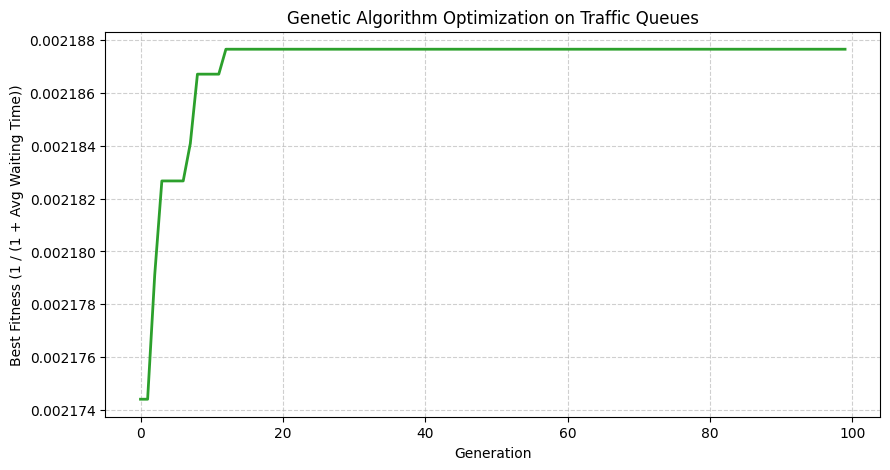

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(range(len(best_fitness_history)), best_fitness_history, color='tab:green', linewidth=2)
plt.xlabel('Generation')
plt.ylabel('Best Fitness (1 / (1 + Avg Waiting Time))')
plt.title('Genetic Algorithm Optimization on Traffic Queues')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()